<a href="https://colab.research.google.com/github/KV-DHEERAJKUMAR/Hybrid-EfficientNet-Swin-Transformer-Network-with-Cross-Attention-Fusion-for-Brain-Tumor-/blob/main/Hybrid_EfficientNet_Swin_Transformer_Network_with_Cross_Attention_Fusion_for_Brain_Tumor_MRI_Classification_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q timm kagglehub grad-cam
!pip install -q torch torchvision torchaudio

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 40.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import os
import cv2
import timm
import torch
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm import tqdm

import torch.nn as nn
import torch.optim as optim

from torchvision import transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_recall_curve,
    roc_curve,
    auc
)

from sklearn.preprocessing import label_binarize

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using Device:", device)

Using Device: cuda


In [ ]:
import kagglehub

path = kagglehub.dataset_download(
    "masoudnickparvar/brain-tumor-mri-dataset"
)

print("Dataset Path:", path)

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Dataset Path: /kaggle/input/brain-tumor-mri-dataset


In [ ]:
train_dir = os.path.join(path, "Training")
test_dir = os.path.join(path, "Testing")

print("Training Folder:", train_dir)
print("Testing Folder:", test_dir)

print("\nClasses:")
print(os.listdir(train_dir))

Training Folder: /kaggle/input/brain-tumor-mri-dataset/Training
Testing Folder: /kaggle/input/brain-tumor-mri-dataset/Testing

Classes:
['pituitary', 'notumor', 'meningioma', 'glioma']


In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 16

train_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

In [ ]:
train_dataset = ImageFolder(
    train_dir,
    transform=train_transform
)

test_dataset = ImageFolder(
    test_dir,
    transform=test_transform
)

print("Train Images:", len(train_dataset))
print("Test Images:", len(test_dataset))

print("Classes:", train_dataset.classes)

Train Images: 5600
Test Images: 1600
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

class_names = train_dataset.classes

print(class_names)

['glioma', 'meningioma', 'notumor', 'pituitary']


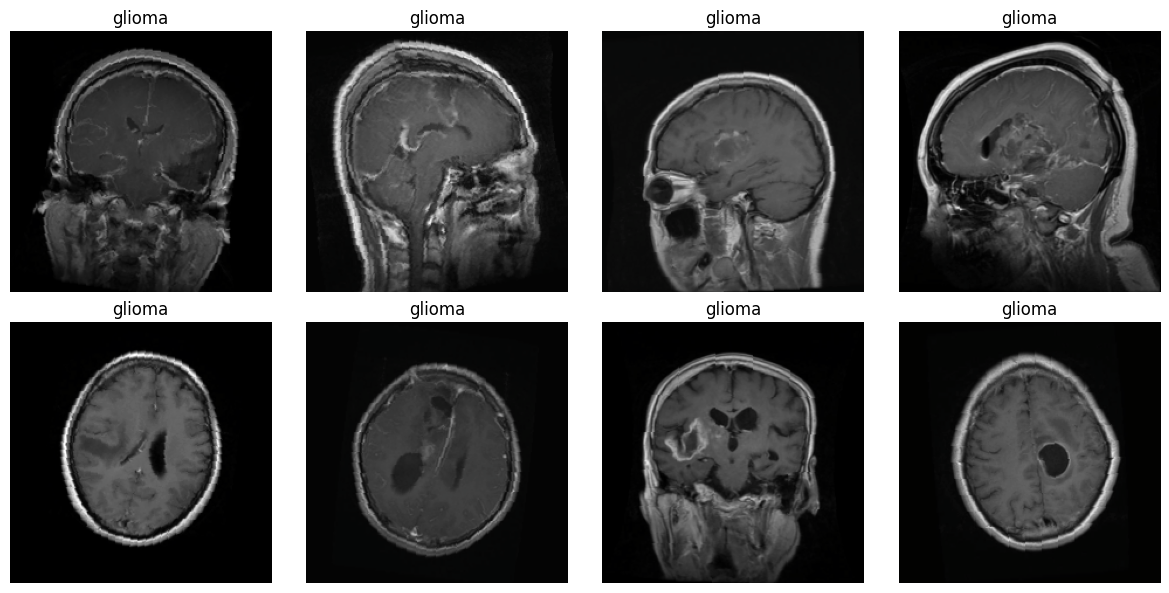

In [ ]:
fig, axes = plt.subplots(2,4, figsize=(12,6))

for i in range(8):
    img, label = train_dataset[i]

    img = img.permute(1,2,0).numpy()

    img = img * np.array([0.229,0.224,0.225])
    img = img + np.array([0.485,0.456,0.406])

    img = np.clip(img,0,1)

    axes[i//4,i%4].imshow(img)
    axes[i//4,i%4].set_title(class_names[label])
    axes[i//4,i%4].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import timm
import torch
import torch.nn as nn

# =====================================================
# Cross Attention Fusion Block
# =====================================================

class CrossAttentionFusion(nn.Module):
    def __init__(self, dim):
        super().__init__()

        self.query = nn.Linear(dim, dim)
        self.key = nn.Linear(dim, dim)
        self.value = nn.Linear(dim, dim)

        self.softmax = nn.Softmax(dim=-1)

    def forward(self, cnn_feat, vit_feat):

        Q = self.query(cnn_feat)
        K = self.key(vit_feat)
        V = self.value(vit_feat)

        attention = self.softmax(
            torch.matmul(Q, K.transpose(-2, -1))
            / (cnn_feat.size(-1) ** 0.5)
        )

        fusion = torch.matmul(attention, V)

        return fusion.squeeze(1)

# =====================================================
# Hybrid Model
# =====================================================

class HybridBrainTumorNet(nn.Module):

    def __init__(self, num_classes=4):
        super().__init__()

        # EfficientNet-B3 Branch
        self.efficientnet = timm.create_model(
            'efficientnet_b3',
            pretrained=True,
            num_classes=0
        )

        eff_dim = self.efficientnet.num_features

        # Swin Tiny Branch
        self.swin = timm.create_model(
            'swin_tiny_patch4_window7_224',
            pretrained=True,
            num_classes=0
        )

        swin_dim = self.swin.num_features

        # Feature Alignment
        self.eff_proj = nn.Linear(eff_dim, 512)
        self.swin_proj = nn.Linear(swin_dim, 512)

        # Cross Attention
        self.cross_attention = CrossAttentionFusion(512)

        # Feature Enhancement
        self.feature_fusion = nn.Sequential(
            nn.Linear(512, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.3)
        )

        # Classification Head
        self.classifier = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(256, num_classes)
        )

    def forward(self, x):

        # CNN Features
        eff_feat = self.efficientnet(x)

        # Transformer Features
        swin_feat = self.swin(x)

        # Projection
        eff_feat = self.eff_proj(eff_feat)
        swin_feat = self.swin_proj(swin_feat)

        # Add sequence dimension
        eff_feat = eff_feat.unsqueeze(1)
        swin_feat = swin_feat.unsqueeze(1)

        # Cross Attention Fusion
        fused = self.cross_attention(
            eff_feat,
            swin_feat
        )

        fused = self.feature_fusion(fused)

        output = self.classifier(fused)

        return output


# =====================================================
# Initialize Model
# =====================================================

model = HybridBrainTumorNet(
    num_classes=len(class_names)
).to(device)

print(model)

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print(f"\nTotal Parameters: {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/49.3M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

HybridBrainTumorNet(
  (efficientnet): EfficientNet(
    (conv_stem): Conv2d(3, 40, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (bn1): BatchNormAct2d(
      40, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
      (drop): Identity()
      (act): SiLU(inplace=True)
    )
    (blocks): Sequential(
      (0): Sequential(
        (0): DepthwiseSeparableConv(
          (conv_dw): Conv2d(40, 40, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=40, bias=False)
          (bn1): BatchNormAct2d(
            40, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
            (drop): Identity()
            (act): SiLU(inplace=True)
          )
          (aa): Identity()
          (se): SqueezeExcite(
            (conv_reduce): Conv2d(40, 10, kernel_size=(1, 1), stride=(1, 1))
            (act1): SiLU(inplace=True)
            (conv_expand): Conv2d(10, 40, kernel_size=(1, 1), stride=(1, 1))
            (gate): Sigmoid()
          )
        

In [ ]:
sample_batch = next(iter(train_loader))

images, labels = sample_batch

images = images.to(device)

with torch.no_grad():
    outputs = model(images)

print("Input Shape :", images.shape)
print("Output Shape:", outputs.shape)

Input Shape : torch.Size([16, 3, 224, 224])
Output Shape: torch.Size([16, 4])


In [ ]:
# =====================================================
# FOCAL LOSS
# =====================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

class FocalLoss(nn.Module):
    def __init__(self,
                 alpha=1,
                 gamma=2,
                 reduction='mean'):
        super(FocalLoss, self).__init__()

        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, inputs, targets):

        ce_loss = F.cross_entropy(
            inputs,
            targets,
            reduction='none'
        )

        pt = torch.exp(-ce_loss)

        focal_loss = self.alpha * (
            (1 - pt) ** self.gamma
        ) * ce_loss

        if self.reduction == 'mean':
            return focal_loss.mean()

        elif self.reduction == 'sum':
            return focal_loss.sum()

        else:
            return focal_loss


criterion = FocalLoss(
    alpha=1,
    gamma=2
)

print("Focal Loss Initialized")

Focal Loss Initialized


In [ ]:
# =====================================================
# OPTIMIZER
# =====================================================

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

# =====================================================
# LR SCHEDULER
# =====================================================

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='max',
    factor=0.5,
    patience=2
)

print("Optimizer & Scheduler Ready")

Optimizer & Scheduler Ready


In [ ]:
# =====================================================
# TRAINING FUNCTION
# =====================================================

def train_one_epoch(model,
                    loader,
                    criterion,
                    optimizer):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, preds = torch.max(
            outputs,
            1
        )

        total += labels.size(0)

        correct += (
            preds == labels
        ).sum().item()

    epoch_loss = (
        running_loss / len(loader)
    )

    epoch_acc = (
        100 * correct / total
    )

    return epoch_loss, epoch_acc

In [ ]:
# =====================================================
# VALIDATION FUNCTION
# =====================================================

def validate(model,
             loader,
             criterion):

    model.eval()

    running_loss = 0

    correct = 0
    total = 0

    all_labels = []
    all_preds = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            running_loss += loss.item()

            _, preds = torch.max(
                outputs,
                1
            )

            total += labels.size(0)

            correct += (
                preds == labels
            ).sum().item()

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_preds.extend(
                preds.cpu().numpy()
            )

    epoch_loss = (
        running_loss / len(loader)
    )

    epoch_acc = (
        100 * correct / total
    )

    return (
        epoch_loss,
        epoch_acc,
        all_labels,
        all_preds
    )

In [ ]:
# =====================================================
# TRAIN MODEL
# =====================================================

EPOCHS = 25

train_losses = []
val_losses = []

train_accs = []
val_accs = []

best_acc = 0

for epoch in range(EPOCHS):

    print(
        f"\nEpoch [{epoch+1}/{EPOCHS}]"
    )

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    val_loss, val_acc, _, _ = validate(
        model,
        test_loader,
        criterion
    )

    scheduler.step(val_acc)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(
        f"Train Loss: {train_loss:.4f}"
    )

    print(
        f"Train Acc : {train_acc:.2f}%"
    )

    print(
        f"Val Loss  : {val_loss:.4f}"
    )

    print(
        f"Val Acc   : {val_acc:.2f}%"
    )

    if val_acc > best_acc:

        best_acc = val_acc

        torch.save(
            model.state_dict(),
            "best_hybrid_model.pth"
        )

        print(
            "Best Model Saved!"
        )

print(
    f"\nBest Validation Accuracy: {best_acc:.2f}%"
)


Epoch [1/25]
Train Loss: 0.1992
Train Acc : 85.11%
Val Loss  : 0.1688
Val Acc   : 91.25%
Best Model Saved!

Epoch [2/25]
Train Loss: 0.0740
Train Acc : 93.93%
Val Loss  : 0.1777
Val Acc   : 91.62%
Best Model Saved!

Epoch [3/25]
Train Loss: 0.0492
Train Acc : 95.98%
Val Loss  : 0.2205
Val Acc   : 93.12%
Best Model Saved!

Epoch [4/25]
Train Loss: 0.0411
Train Acc : 96.79%
Val Loss  : 0.1374
Val Acc   : 94.31%
Best Model Saved!

Epoch [5/25]
Train Loss: 0.0458
Train Acc : 96.16%
Val Loss  : 0.1768
Val Acc   : 93.25%

Epoch [6/25]
Train Loss: 0.0364
Train Acc : 96.93%
Val Loss  : 0.1644
Val Acc   : 94.94%
Best Model Saved!

Epoch [7/25]
Train Loss: 0.0372
Train Acc : 96.88%
Val Loss  : 0.1517
Val Acc   : 95.31%
Best Model Saved!

Epoch [8/25]
Train Loss: 0.0249
Train Acc : 98.14%
Val Loss  : 0.1358
Val Acc   : 95.06%

Epoch [9/25]
Train Loss: 0.0200
Train Acc : 98.29%
Val Loss  : 0.1429
Val Acc   : 93.75%

Epoch [10/25]
Train Loss: 0.0285
Train Acc : 97.55%
Val Loss  : 0.1723
Val Acc   

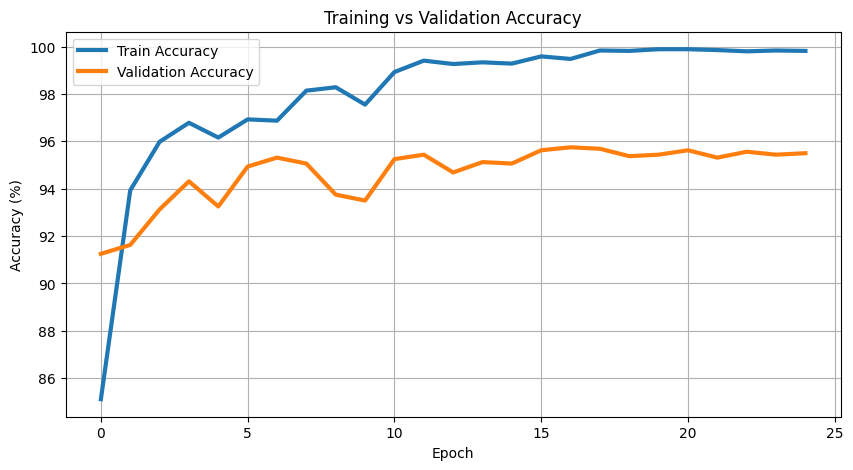

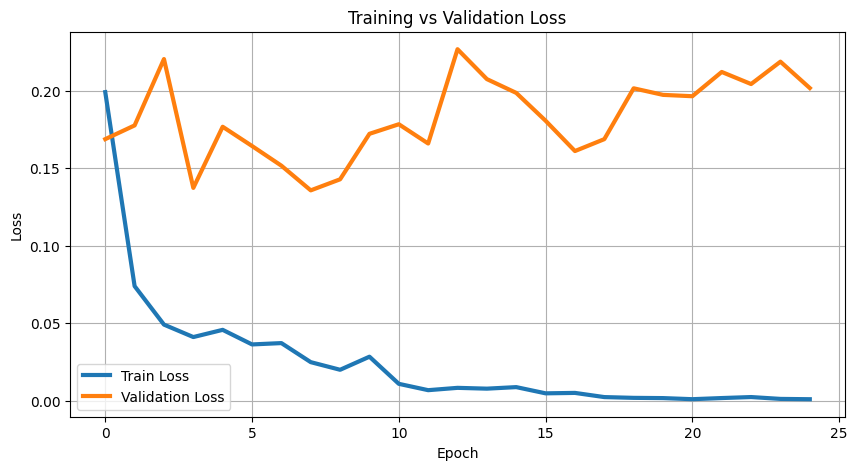

In [ ]:
# =====================================================
# ACCURACY CURVE
# =====================================================

plt.figure(figsize=(10,5))

plt.plot(
    train_accs,
    label="Train Accuracy",
    linewidth=3
)

plt.plot(
    val_accs,
    label="Validation Accuracy",
    linewidth=3
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training vs Validation Accuracy")

plt.legend()
plt.grid(True)

plt.show()


# =====================================================
# LOSS CURVE
# =====================================================

plt.figure(figsize=(10,5))

plt.plot(
    train_losses,
    label="Train Loss",
    linewidth=3
)

plt.plot(
    val_losses,
    label="Validation Loss",
    linewidth=3
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# =====================================================
# LOAD BEST MODEL
# =====================================================

model.load_state_dict(
    torch.load(
        "best_hybrid_model.pth",
        map_location=device
    )
)

model.eval()

print("Best Model Loaded Successfully!")

Best Model Loaded Successfully!


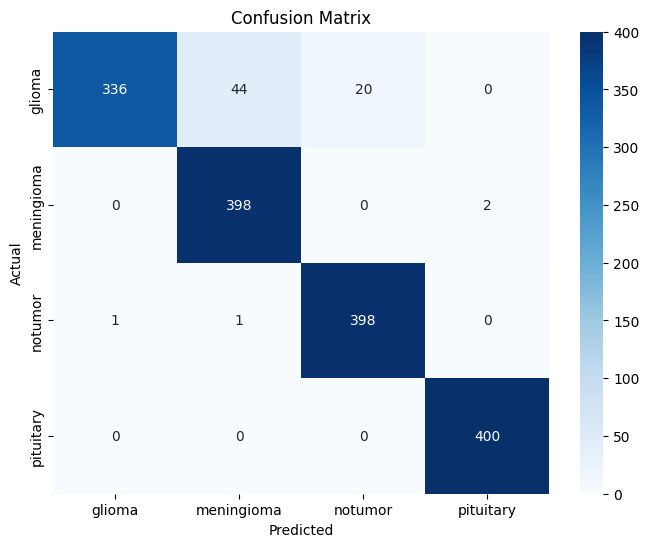

In [ ]:
# =====================================================
# CONFUSION MATRIX
# =====================================================

from sklearn.metrics import confusion_matrix
import seaborn as sns

all_preds = []
all_labels = []

model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        _, preds = torch.max(outputs, 1)

        all_preds.extend(
            preds.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )

cm = confusion_matrix(
    all_labels,
    all_preds
)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [ ]:
# =====================================================
# CLASSIFICATION REPORT
# =====================================================

from sklearn.metrics import classification_report

report = classification_report(
    all_labels,
    all_preds,
    target_names=class_names
)

print(report)

              precision    recall  f1-score   support

      glioma       1.00      0.84      0.91       400
  meningioma       0.90      0.99      0.94       400
     notumor       0.95      0.99      0.97       400
   pituitary       1.00      1.00      1.00       400

    accuracy                           0.96      1600
   macro avg       0.96      0.96      0.96      1600
weighted avg       0.96      0.96      0.96      1600



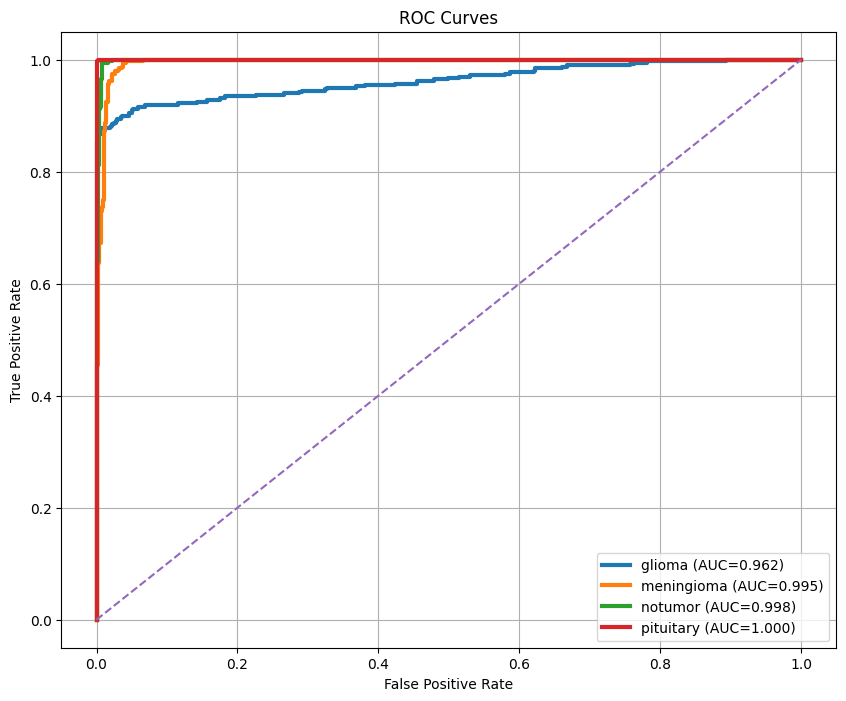

In [ ]:
# =====================================================
# ROC CURVES
# =====================================================

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

y_true = []
y_score = []

model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        probs = torch.softmax(
            outputs,
            dim=1
        )

        y_true.extend(
            labels.numpy()
        )

        y_score.extend(
            probs.cpu().numpy()
        )

y_true = np.array(y_true)
y_score = np.array(y_score)

n_classes = len(class_names)

y_true_bin = label_binarize(
    y_true,
    classes=np.arange(n_classes)
)

plt.figure(figsize=(10,8))

for i in range(n_classes):

    fpr, tpr, _ = roc_curve(
        y_true_bin[:, i],
        y_score[:, i]
    )

    roc_auc = auc(
        fpr,
        tpr
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=3,
        label=f"{class_names[i]} (AUC={roc_auc:.3f})"
    )

plt.plot(
    [0,1],
    [0,1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")

plt.legend()
plt.grid()

plt.show()

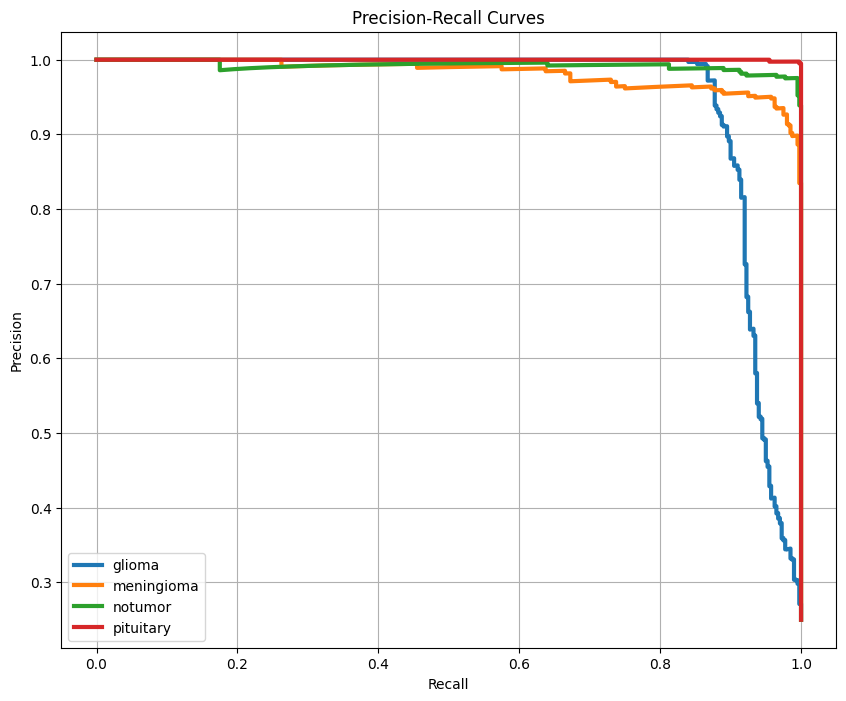

In [ ]:
# =====================================================
# PRECISION RECALL CURVES
# =====================================================

from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(10,8))

for i in range(n_classes):

    precision, recall, _ = precision_recall_curve(
        y_true_bin[:, i],
        y_score[:, i]
    )

    plt.plot(
        recall,
        precision,
        linewidth=3,
        label=class_names[i]
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves")

plt.legend()
plt.grid()

plt.show()

In [ ]:
target_layers = [
    model.efficientnet.conv_head
]

In [ ]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

target_layers = [
    model.efficientnet.conv_head
]

cam = GradCAM(
    model=model,
    target_layers=target_layers
)

In [ ]:
from google.colab import files

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

print(image_path)

Saving meni.jpg to meni.jpg
meni.jpg


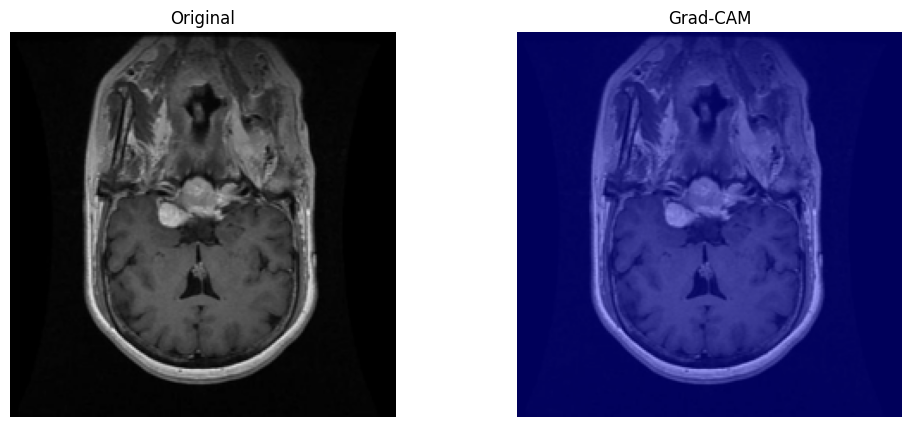

In [ ]:
from PIL import Image

image = Image.open(
    image_path
).convert("RGB")

rgb_img = np.array(
    image.resize((224,224))
).astype(np.float32) / 255.0

input_tensor = test_transform(
    image
).unsqueeze(0).to(device)

grayscale_cam = cam(
    input_tensor=input_tensor
)[0]

visualization = show_cam_on_image(
    rgb_img,
    grayscale_cam,
    use_rgb=True
)

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(rgb_img)
plt.title("Original")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(visualization)
plt.title("Grad-CAM")
plt.axis("off")

plt.show()

In [ ]:
# =====================================================
# UPLOAD MRI IMAGE
# =====================================================

from google.colab import files

uploaded = files.upload()

image_path = list(
    uploaded.keys()
)[0]

Saving meni.jpg to meni (1).jpg


Prediction : meningioma
Confidence : 97.67%


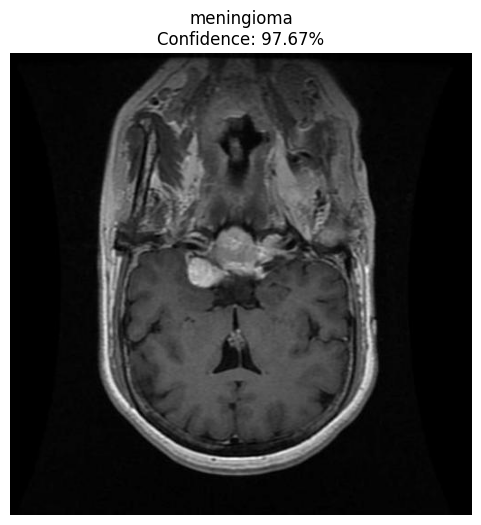

In [ ]:
# =====================================================
# PREDICTION
# =====================================================

image = Image.open(
    image_path
).convert("RGB")

input_tensor = test_transform(
    image
).unsqueeze(0)

input_tensor = input_tensor.to(device)

model.eval()

with torch.no_grad():

    outputs = model(
        input_tensor
    )

    probs = torch.softmax(
        outputs,
        dim=1
    )

    confidence, pred = torch.max(
        probs,
        1
    )

pred_class = class_names[
    pred.item()
]

print(
    f"Prediction : {pred_class}"
)

print(
    f"Confidence : {confidence.item()*100:.2f}%"
)

plt.figure(figsize=(6,6))

plt.imshow(image)

plt.title(
    f"{pred_class}\nConfidence: {confidence.item()*100:.2f}%"
)

plt.axis("off")

plt.show()